Loaded: (15000, 44)
Feature matrix: (15000, 25)

Training Linear Regression...
Training Decision Tree...
Training Random Forest...
Best RF params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}
Training Gradient Boosting...
Best GB params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

Model Results
            Model  RMSE   MAE    R2
    Random Forest 0.188 0.039 1.000
    Decision Tree 0.393 0.099 0.999
Gradient Boosting 0.365 0.229 0.999
Linear Regression 4.506 3.461 0.852


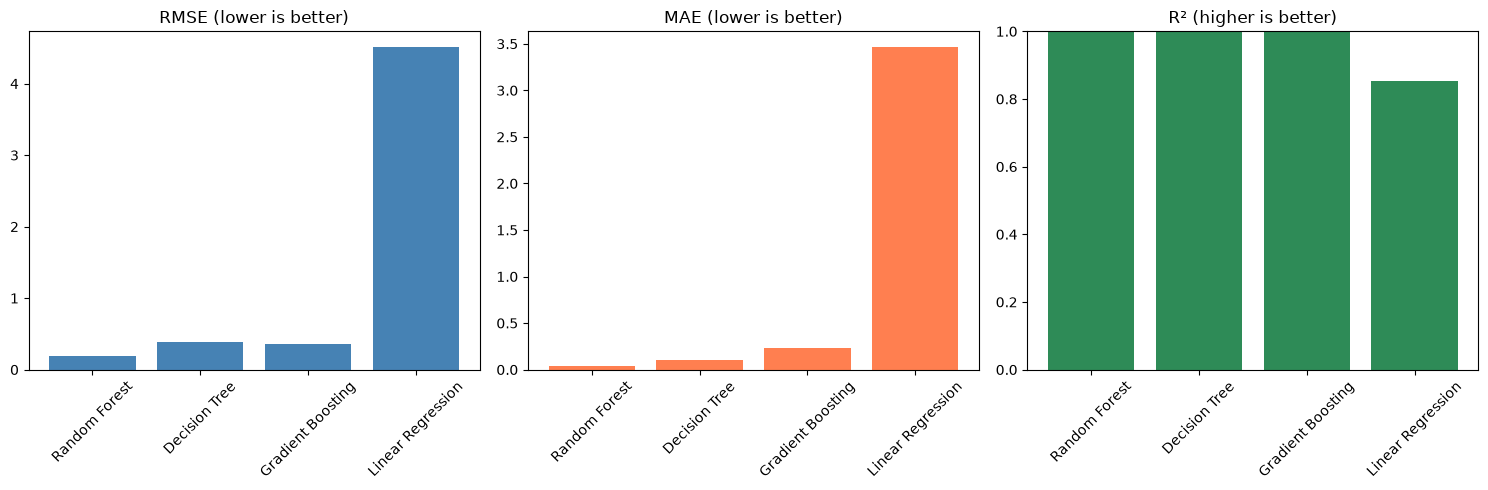


Best model: Random Forest

Top 10 features:
                       Feature  Importance
      Estimated_Delivery_Hours    0.590871
       Promised_Delivery_Hours    0.184359
                  Holiday_Flag    0.147842
      Shipping_Method_Same Day    0.031310
      Shipping_Method_Standard    0.022357
       Shipping_Method_Express    0.016821
                   Distance_KM    0.003626
Warehouse_Capacity_Utilization    0.001650
    Warehouse_Processing_Hours    0.000234
         Traffic_Delay_Minutes    0.000174


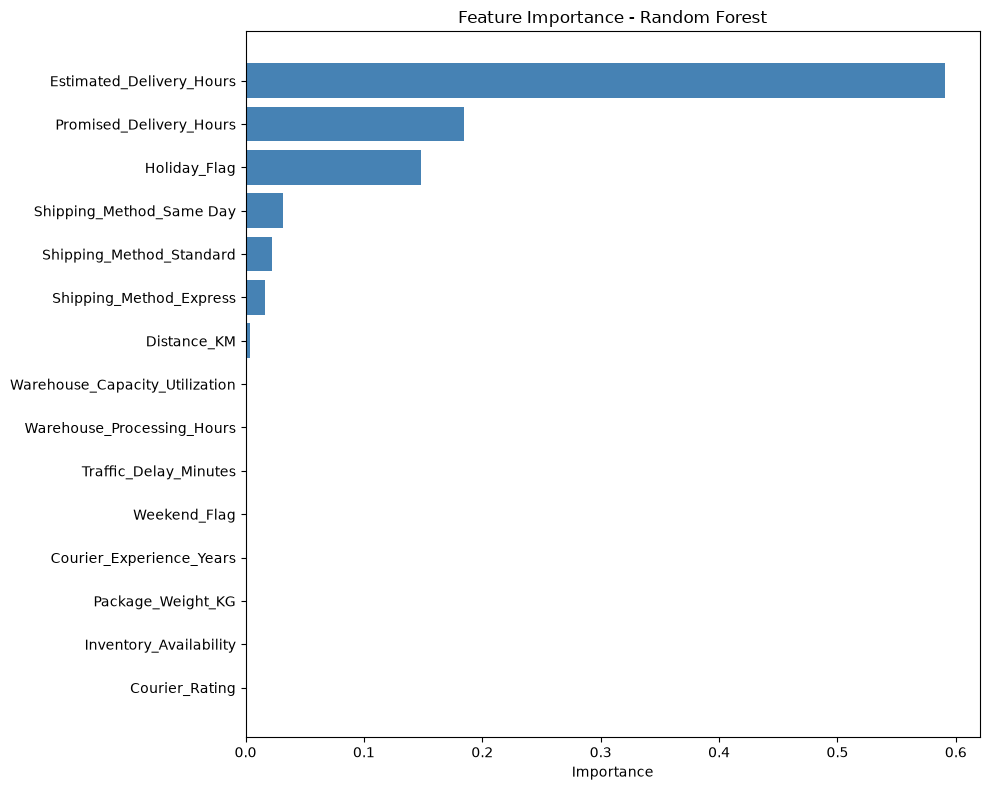

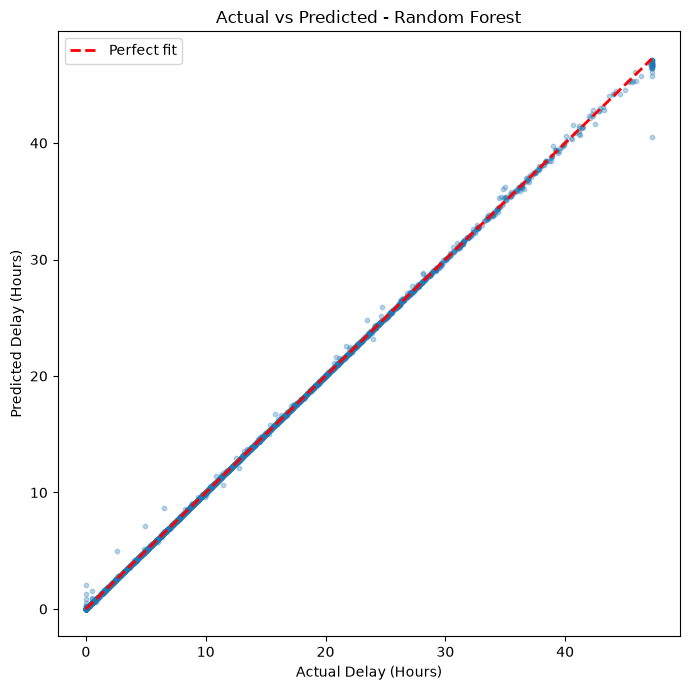


Optimization Insights

Warehouses with highest delays:
Warehouse_Region
North    11.64
West     11.62
South    11.51
Name: Delivery_Delay_Hours, dtype: float64

Slowest delivery partners:
Delivery_Partner
Partner B    11.74
Partner A    11.50
Partner C    11.48
Name: Delivery_Delay_Hours, dtype: float64

High cost-per-km shipments: 1500 (top 10%)
Avg cost per km overall: $0.139
Avg cost per km (high group): $0.282

Weekday avg delay: 11.52 hours
Weekend avg delay: 11.36 hours


In [1]:
"""
Week 4 - Predictive Modeling and Optimization
Logistics Data Analysis Internship
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('logistics_data_cleaned.csv')
print("Loaded:", df.shape)



features = ['Distance_KM', 'Package_Weight_KG',
            'Warehouse_Processing_Hours', 'Traffic_Delay_Minutes',
            'Weather_Delay_Minutes', 'Courier_Rating',
            'Courier_Experience_Years', 'Warehouse_Capacity_Utilization',
            'Inventory_Availability', 'Weekend_Flag', 'Holiday_Flag',
            'Promotion_Flag', 'Estimated_Delivery_Hours',
            'Promised_Delivery_Hours']


for col in ['Warehouse_Region', 'Shipping_Method', 'Delivery_Partner']:
    if col in df.columns:
        dummies = pd.get_dummies(df[col], prefix=col, drop_first=True)
        df = pd.concat([df, dummies], axis=1)
        features += dummies.columns.tolist()

X = df[features].copy()
y = df['Delivery_Delay_Hours']

mask = ~(X.isnull().any(axis=1) | y.isnull())
X = X[mask]
y = y[mask]

print("Feature matrix:", X.shape)



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



models = {}

print("\nTraining Linear Regression...")
lr = LinearRegression()
lr.fit(X_train, y_train)
models['Linear Regression'] = lr

print("Training Decision Tree...")
dt = DecisionTreeRegressor(max_depth=10, min_samples_split=5, random_state=42)
dt.fit(X_train, y_train)
models['Decision Tree'] = dt

print("Training Random Forest...")
rf = RandomForestRegressor(random_state=42)
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5]
}
rf_search = GridSearchCV(rf, rf_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
rf_search.fit(X_train, y_train)
models['Random Forest'] = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)

print("Training Gradient Boosting...")
gb = GradientBoostingRegressor(random_state=42)
gb_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5]
}
gb_search = GridSearchCV(gb, gb_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
gb_search.fit(X_train, y_train)
models['Gradient Boosting'] = gb_search.best_estimator_
print("Best GB params:", gb_search.best_params_)



print("\n" + "=" * 50)
print("Model Results")
print("=" * 50)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'RMSE': round(rmse, 3),
        'MAE': round(mae, 3),
        'R2': round(r2, 3)
    })

results_df = pd.DataFrame(results).sort_values('R2', ascending=False)
print(results_df.to_string(index=False))



fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].bar(results_df['Model'], results_df['RMSE'], color='steelblue')
ax[0].set_title('RMSE (lower is better)')
ax[0].tick_params(axis='x', rotation=45)

ax[1].bar(results_df['Model'], results_df['MAE'], color='coral')
ax[1].set_title('MAE (lower is better)')
ax[1].tick_params(axis='x', rotation=45)

ax[2].bar(results_df['Model'], results_df['R2'], color='seagreen')
ax[2].set_title('R² (higher is better)')
ax[2].set_ylim(0, 1)
ax[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('week4_model_comparison.png', dpi=150)
plt.show()

 

best_name = results_df.iloc[0]['Model']
best_model = models[best_name]
print(f"\nBest model: {best_name}")

if hasattr(best_model, 'feature_importances_'):
    importance = pd.DataFrame({
        'Feature': features,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print("\nTop 10 features:")
    print(importance.head(10).to_string(index=False))

    plt.figure(figsize=(10, 8))
    top15 = importance.head(15).iloc[::-1]
    plt.barh(top15['Feature'], top15['Importance'], color='steelblue')
    plt.xlabel('Importance')
    plt.title(f'Feature Importance - {best_name}')
    plt.tight_layout()
    plt.savefig('week4_feature_importance.png', dpi=150)
    plt.show()



plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions[best_name], alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Perfect fit')
plt.xlabel('Actual Delay (Hours)')
plt.ylabel('Predicted Delay (Hours)')
plt.title(f'Actual vs Predicted - {best_name}')
plt.legend()
plt.tight_layout()
plt.savefig('week4_actual_vs_pred.png', dpi=150)
plt.show()



print("\n" + "=" * 50)
print("Optimization Insights")
print("=" * 50)

wh_delay = df.groupby('Warehouse_Region')['Delivery_Delay_Hours'].mean().sort_values(ascending=False)
print("\nWarehouses with highest delays:")
print(wh_delay.head(3).round(2))

dp_delay = df.groupby('Delivery_Partner')['Delivery_Delay_Hours'].mean().sort_values(ascending=False)
print("\nSlowest delivery partners:")
print(dp_delay.head(3).round(2))

if 'cost_per_km' in df.columns:
    high_cost = df[df['cost_per_km'] > df['cost_per_km'].quantile(0.9)]
    print(f"\nHigh cost-per-km shipments: {len(high_cost)} (top 10%)")
    print(f"Avg cost per km overall: ${df['cost_per_km'].mean():.3f}")
    print(f"Avg cost per km (high group): ${high_cost['cost_per_km'].mean():.3f}")

if 'is_weekend' in df.columns:
    wk = df.groupby('is_weekend')['Delivery_Delay_Hours'].mean()
    print(f"\nWeekday avg delay: {wk.get(0, 0):.2f} hours")
    print(f"Weekend avg delay: {wk.get(1, 0):.2f} hours")


